# Econ 524 — Lab: Identification of Causal Effects
## Potential Outcomes, Unconfoundedness, Instrumental Variables and LATE


| Session | Date | Slides | Content |
|---|---|---|---|
| **Part A** | Fri 16 Oct | 5–11 | Potential outcomes, selection bias, unconfoundedness, overlap, matching by stratification |
| **Part B** | Fri 23 Oct | 13–28 | Incomplete randomization, compliance types, ITT, Wald, LATE, LATE with covariates |

**The design principle of every simulation below.** We generate *both* potential outcomes for
every unit, so we always know the true parameter. Each estimator then only gets to see what a
real dataset would contain: $(Y, D, Z)$ in Part A and $(Y, D, W, Z)$ in Part B. The gap between
the two is the whole subject of identification.

**Notation follows the slides**: $Y(1), Y(0)$ for potential outcomes, $D$ for
treatment, $Z$ for controls, and $W$ for the instrument.

**Original sources behind the ideas**
- Potential outcomes: Neyman (1923) for experiments; Rubin (1974) for observational data.
- Unconfoundedness + overlap ("strong ignorability"): Rosenbaum & Rubin (1983, *Biometrika*);
  review in Imbens (2004, *REStat*).
- What OLS with controls actually estimates: Angrist (1998, *Econometrica*).
- LATE: Imbens & Angrist (1994, *Econometrica*); compliance types: Angrist, Imbens & Rubin
  (1996, *JASA*); "uniformity" terminology: Heckman & Vytlacil (2005, *Econometrica*).
- One-sided non-compliance: Bloom (1984, *Evaluation Review*).
- Complier characteristics and IV with covariates: Abadie (2003, *J. Econometrics*).
- ML for nuisance functions: Chernozhukov, Hansen, Kallus, Spindler & Syrgkanis (2024),
  *Applied Causal Inference Powered by ML and AI* (CausalML book).

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (7, 4)

---
# PART A — Potential Outcomes and Unconfoundedness  *(Fri 16 Oct, 50 min)*


**By the end of Part A you should be able to:**
1. Write the switching equation in code and say which column of a potential-outcomes table is
   never observed.
2. Verify the slide-8 identity $\text{SDO} = \theta_{ATT} + \text{selection bias}$ numerically.
3. Recover $\theta_{ATE}$ and $\theta_{ATT}$ with the three-step *classify–compare–aggregate*
   recipe of slide 11.
4. Explain why "regress $Y$ on $D$ and dummies for $Z$" is **not** the same as the slide-11 ATE.
5. Say which parameter survives when overlap fails, and why the cell-by-cell recipe breaks when
   $Z$ is high-dimensional.

---
## A0 Warm-up (5 min, no code)

A state workforce agency runs a job-training program. Caseworkers can see each applicant's
**education level** and steer applicants toward the program. They push hardest on the applicants
they think are least employable, because that is their job.

Discuss with your neighbour:

1. Will the average 1-year earnings of trainees be higher or lower than those of non-trainees?
   Does that tell you the program hurts?
2. Suppose caseworkers decide **only** on education. Within the group of high-school graduates,
   is training "as if random"?
3. Now suppose caseworkers also see something we don't — how motivated the applicant looks in the
   interview. Does your answer to (2) change?

Question 2 is unconfoundedness (slide 9). Question 3 is the reason it is an *assumption*.

---
## A1 Potential outcomes and the naive comparison 

### The data-generating process

$n = 50{,}000$ applicants. $Z \in \{\text{dropout}, \text{hs}, \text{somecol}, \text{ba}\}$ is
education. Outcomes are 1-year earnings in **\$1,000s**.

- $Y(0)$ rises steeply with education.
- The treatment effect $Y(1) - Y(0)$ **falls** with education: the program teaches skills the
  BA holders already have.
- The caseworker's assignment rule depends **only on $Z$** — training is most likely for
  dropouts. Within a cell, assignment is a coin flip. So unconfoundedness holds **by
  construction**.

| $Z$ | share | mean $Y(0)$ | mean effect | $P(D=1 \mid Z)$ |
|---|---|---|---|---|
| dropout | 0.20 | 12 | 4.0 | 0.70 |
| hs | 0.35 | 20 | 3.0 | 0.45 |
| somecol | 0.25 | 26 | 2.0 | 0.25 |
| ba | 0.20 | 38 | 0.5 | 0.10 |

In [2]:
rng = np.random.default_rng(20261016)

EDU     = np.array(["dropout", "hs", "somecol", "ba"])
P_Z     = np.array([0.20, 0.35, 0.25, 0.20])
MU_Y0   = np.array([12.0, 20.0, 26.0, 38.0])   # mean Y(0) by cell, $1000s
MU_TE   = np.array([ 4.0,  3.0,  2.0,  0.5])   # mean treatment effect by cell
PSCORE  = np.array([0.70, 0.45, 0.25, 0.10])   # P(D = 1 | Z), the propensity score

def simulate_training(n, pscore=PSCORE, gamma_u=0.0, rng=rng):
    '''Job-training DGP.  gamma_u > 0 lets an UNOBSERVED trait u shift
    both treatment take-up and Y(0) -- used in A4 to break unconfoundedness.'''
    j  = rng.choice(4, size=n, p=P_Z)
    u  = rng.normal(size=n)                                   # unobserved "employability"
    y0 = MU_Y0[j] + 3.0 * gamma_u * u + rng.normal(0, 6, n)
    y1 = y0 + MU_TE[j] + rng.normal(0, 1, n)
    # assignment: cell propensity, shifted by u only if gamma_u > 0
    logit = np.log(pscore[j] / (1 - pscore[j]) + 1e-12) - 1.5 * gamma_u * u
    d  = rng.binomial(1, 1 / (1 + np.exp(-logit)))
    y  = d * y1 + (1 - d) * y0                                # switching equation (slide 5)
    return pd.DataFrame({"z": pd.Categorical(EDU[j], categories=EDU),
                         "d": d, "y": y, "y0": y0, "y1": y1})

df = simulate_training(50_000)
df.head(8)

,z,d,y,y0,y1
0,hs,0,21.029,21.029,25.491
1,somecol,1,31.646,29.435,31.646
2,somecol,0,26.257,26.257,27.366
3,hs,1,24.460,20.210,24.460
4,somecol,0,23.944,23.944,25.464
5,hs,0,33.537,33.537,35.387
6,dropout,1,20.545,16.364,20.545
7,hs,1,22.313,18.774,22.313


The table above is a *God's-eye view*. In any real dataset, for each row, **exactly one** of
`y0`, `y1` would be missing — `y0` for trainees, `y1` for everyone else (slide 7). Make that
concrete before going on:

In [3]:
observed = df[["z", "d", "y"]].copy()
observed["y1 (seen?)"] = np.where(df.d == 1, df.y1, np.nan)
observed["y0 (seen?)"] = np.where(df.d == 0, df.y0, np.nan)
observed.head(8)

,z,d,y,y1 (seen?),y0 (seen?)
0,hs,0,21.029,NaN,21.029
1,somecol,1,31.646,31.646,NaN
2,somecol,0,26.257,NaN,26.257
3,hs,1,24.460,24.460,NaN
4,somecol,0,23.944,NaN,23.944
5,hs,0,33.537,NaN,33.537
6,dropout,1,20.545,20.545,NaN
7,hs,1,22.313,22.313,NaN


### Exercise A1 (6 min)

Using the God's-eye `df`:

1. Compute $\theta_{ATE} = E[Y(1) - Y(0)]$ and $\theta_{ATT} = E[Y(1) - Y(0) \mid D = 1]$
   (slide 6).
2. Compute the naive comparison $\text{SDO} = E[Y \mid D=1] - E[Y \mid D=0]$ using only `y`
   and `d`.
3. Compute the selection bias $E[Y(0) \mid D=1] - E[Y(0) \mid D=0]$ and verify the slide-8
   identity $\text{SDO} = \theta_{ATT} + \text{selection bias}$.

**Predict first:** sign of the SDO?

In [4]:
# ---- EXERCISE A1 ------------------------------------------------------------
te  = df.y1 - df.y0
ATE = te.mean()
ATT = te[df.d == 1].mean()

SDO = df.y[df.d == 1].mean() - df.y[df.d == 0].mean()
SEL = df.y0[df.d == 1].mean() - df.y0[df.d == 0].mean()

pd.Series({"ATE (true)": ATE, "ATT (true)": ATT, "SDO (naive)": SDO,
           "selection bias": SEL, "ATT + selection bias": ATT + SEL})
# -----------------------------------------------------------------------------

ATE (true)              2.453
ATT (true)              3.065
SDO (naive)            -4.329
selection bias         -7.394
ATT + selection bias   -4.329
dtype: float64

**Reading the numbers.** Every cell has a *positive* effect, the ATE is about $+2.4$k and the ATT
about $+3.1$k, yet the naive comparison says trainees earn roughly **\$4,000 less**. The
selection-bias term (about $-7$k) says: had the trainees *not* been trained, they would have
earned about \$7,000 less than the non-trainees anyway. The caseworkers did their job, and that
broke the comparison.

**Connecting to the Econ 521 notebook.** There we used a *three-term* identity,
$\text{SDO} = \text{ATE} + \text{selection bias} + (1-\pi)(\text{ATT} - \text{ATU})$.
The slides use a *two-term* version targeting the ATT. Both are identities; they differ only in
which parameter you peel off first. If the target is the ATT, the heterogeneity term disappears
because it is absorbed into the ATT itself. Exercise for home: derive one from the other by
writing $\text{ATE} = \pi\,\text{ATT} + (1-\pi)\,\text{ATU}$.

Also notice $\theta_{ATT} > \theta_{ATE}$ here: trainees are concentrated in the low-education
cells, which are exactly the cells with large effects. The ATT is a different *population*, not
a noisy version of the ATE.

---
## A2 Unconfoundedness and matching by stratification (slides 9–11)

**Assumption 1.1 (Unconfoundedness).** $(Y(0), Y(1)) \perp D \mid Z$.
**Assumption 1.2 (Overlap).** $0 < P(D = 1 \mid Z = z) < 1$ for all $z$.

Together these are what Rosenbaum & Rubin (1983) called **strong ignorability**. The
identification step (slide 10) is a two-line argument worth saying out loud:

$$
E[Y \mid Z, D=1] \;=\; E[Y(1) \mid Z, D=1] \;\overset{\text{1.1}}{=}\; E[Y(1) \mid Z],
$$

and the same with $D=0$ and $Y(0)$. Overlap guarantees both conditional means *exist* (there are
units on both sides in every cell). Then take the outer expectation over $Z$ for the ATE, or over
$Z \mid D = 1$ for the ATT.

**The three-step recipe (slide 11) for discrete $Z$:**
1. **Classify** units into cells $z_1, \dots, z_J$.
2. **Compare** within cells: $\Delta_j = E[Y \mid Z=z_j, D=1] - E[Y \mid Z=z_j, D=0]$.
3. **Aggregate**: $\theta_{ATE} = \sum_j \Delta_j\, P(Z = z_j)$ and
   $\theta_{ATT} = \sum_j \Delta_j\, P(Z = z_j \mid D = 1)$.

The only thing that changes between the ATE and the ATT is the **weights**.

### Exercise A2 (7 min)

Write `stratify(data)` that uses **only** `z`, `d`, `y` and returns a table with one row per
cell: `delta_j`, `P(Z=z)`, `P(Z=z|D=1)`, and the cell's propensity `P(D=1|Z=z)`. Then
aggregate to the ATE and ATT and compare them with the truth from A1.

In [5]:
# ---- EXERCISE A2 ------------------------------------------------------------
def stratify(data):
    '''Classify - compare - aggregate (slide 11). Uses only observables (y, d, z).'''
    g = data.groupby("z", observed=True)
    tab = pd.DataFrame({
        "mean_y_treated":   g.apply(lambda s: s.y[s.d == 1].mean()),
        "mean_y_untreated": g.apply(lambda s: s.y[s.d == 0].mean()),
        "P(Z=z)":           g.size() / len(data),
        "P(Z=z|D=1)":       g.d.sum() / data.d.sum(),
        "P(D=1|Z=z)":       g.d.mean(),
    })
    tab["delta_j"] = tab.mean_y_treated - tab.mean_y_untreated
    return tab

tab = stratify(df)
ATE_hat = (tab.delta_j * tab["P(Z=z)"]).sum()
ATT_hat = (tab.delta_j * tab["P(Z=z|D=1)"]).sum()

display(tab.round(3))
pd.DataFrame({"truth": [ATE, ATT], "stratification": [ATE_hat, ATT_hat]},
             index=["ATE", "ATT"])
# -----------------------------------------------------------------------------

,mean_y_treated,mean_y_untreated,P(Z=z),P(Z=z|D=1),P(D=1|Z=z),delta_j
z,,,,,,
dropout,15.903,11.820,0.200,0.372,0.705,4.083
hs,22.980,19.900,0.354,0.417,0.448,3.080
somecol,27.958,26.052,0.247,0.161,0.248,1.906
ba,38.555,38.065,0.199,0.050,0.095,0.490


,truth,stratification
ATE,2.453,2.475
ATT,3.065,3.135


Both are recovered up to sampling noise. Each $\Delta_j$ is the causal effect for its cell
(compare it with the `MU_TE` column of the DGP table), and the two parameters are just two
different weighted averages of the same four numbers.

### The regression everyone actually runs

In practice people rarely aggregate by hand. They run

$$Y_i = \alpha + \tau D_i + \sum_j \gamma_j \mathbf 1\{Z_i = z_j\} + \varepsilon_i .$$

Under unconfoundedness, is $\hat\tau$ the ATE? The ATT? Run it.

In [6]:
tau_ols = smf.ols("y ~ d + C(z)", data=df).fit(cov_type="HC1").params["d"]

# Angrist (1998): OLS with saturated dummies for Z weights cell effects by
#   P(Z=z) * p(z) * (1 - p(z)),   i.e. by the conditional VARIANCE of treatment.
w = tab["P(Z=z)"] * tab["P(D=1|Z=z)"] * (1 - tab["P(D=1|Z=z)"])
tau_angrist = (w * tab.delta_j).sum() / w.sum()

weights = pd.DataFrame({
    "delta_j": tab.delta_j,
    "ATE weight": tab["P(Z=z)"],
    "ATT weight": tab["P(Z=z|D=1)"],
    "OLS weight": w / w.sum(),
})
display(weights.round(3))
pd.Series({"ATE (true)": ATE, "ATT (true)": ATT,
           "OLS tau_hat": tau_ols, "Angrist-weighted average": tau_angrist})

,delta_j,ATE weight,ATT weight,OLS weight
z,,,,
dropout,4.083,0.200,0.372,0.217
hs,3.080,0.354,0.417,0.455
somecol,1.906,0.247,0.161,0.239
ba,0.490,0.199,0.050,0.089


ATE (true)                 2.453
ATT (true)                 3.065
OLS tau_hat                2.786
Angrist-weighted average   2.786
dtype: float64

**OLS gives neither.** It gives a third weighted average of the $\Delta_j$, with weights
proportional to $P(Z = z)\,p(z)\,(1 - p(z))$, the *variance* of treatment within each cell. This is
the result in **Angrist (1998, *Econometrica*)**; it also appears in *Mostly Harmless
Econometrics* §3.3.1. The last two numbers agree to machine precision: it is an algebraic fact
about OLS, not an approximation.

**Intuition.** OLS learns about $\tau$ from within-cell variation in $D$. A cell where everyone
(or no one) is treated has no variation and contributes nothing. A cell with a 50/50 split
contributes the most. That is a statement about where the *information* is, and it has nothing to
do with which population we care about.

Here the regression overweights **hs** ($p \approx 0.45$, close to $0.5$) and underweights
**dropout** ($p \approx 0.70$) and **ba** ($p \approx 0.10$). The gap with the ATE is moderate
here; it can be large when effects and propensities move together across cells.

> **Take-away:** with homogeneous effects, all three numbers coincide. With heterogeneity, "the
> coefficient on $D$ with controls" is a well-defined causal object, but you have to name its
> weights before you can call it the ATE.

---
## A3 When overlap fails (7 min)

The agency changes policy: **BA holders are no longer eligible**, so $P(D=1 \mid Z=\text{ba}) = 0$.
Unconfoundedness still holds, but Assumption 1.2 fails for one cell.

### Exercise A3

1. Re-simulate with the new propensity vector and rerun `stratify`. What happens to
   $\Delta_{\text{ba}}$?
2. Can you still compute $\hat\theta_{ATE}$? Can you still compute $\hat\theta_{ATT}$?
3. What does the OLS-with-dummies regression report, and for whom?

In [7]:
# ---- EXERCISE A3 ------------------------------------------------------------
df_no = simulate_training(50_000, pscore=np.array([0.70, 0.45, 0.25, 0.0]))
tab_no = stratify(df_no)
display(tab_no.round(3))

te_no      = df_no.y1 - df_no.y0
ATT_no_hat = (tab_no.delta_j * tab_no["P(Z=z|D=1)"]).sum(min_count=1)   # ba weight is 0
ATE_no_hat = (tab_no.delta_j * tab_no["P(Z=z)"]).sum(min_count=4)       # needs all 4 cells

pd.DataFrame({
    "truth": [te_no.mean(), te_no[df_no.d == 1].mean()],
    "stratification": [ATE_no_hat, ATT_no_hat],
}, index=["ATE", "ATT"])
# -----------------------------------------------------------------------------

,mean_y_treated,mean_y_untreated,P(Z=z),P(Z=z|D=1),P(D=1|Z=z),delta_j
z,,,,,,
dropout,15.924,11.999,0.199,0.385,0.700,3.925
hs,23.072,19.987,0.351,0.443,0.457,3.085
somecol,27.945,25.983,0.250,0.172,0.249,1.962
ba,NaN,37.976,0.200,0.000,0.000,NaN


,truth,stratification
ATE,2.451,NaN
ATT,3.205,3.216


In [8]:
# The regression runs without complaint -- that is the danger.
tau_no = smf.ols("y ~ d + C(z)", data=df_no).fit().params["d"]
print(f"OLS with dummies, no-BA-eligibility world: {tau_no:.3f}")
print("(It silently drops the ba cell's information: zero weight, since p(1-p) = 0 there.)")

OLS with dummies, no-BA-eligibility world: 2.987
(It silently drops the ba cell's information: zero weight, since p(1-p) = 0 there.)


**What happened.**

- $\Delta_{\text{ba}}$ is `NaN`: there are no treated BA holders, so
  $E[Y \mid Z=\text{ba}, D=1]$ is undefined. **The ATE is not identified.** No estimator can fix
  this; the data contain no information about $Y(1)$ for BA holders.
- The ATT is **still identified**, because its weights $P(Z = z \mid D = 1)$ are zero exactly
  where the data are missing. For the ATT you only need the weaker condition
  $P(D=1 \mid Z = z) < 1$ (every treated type has untreated twins). Imbens (2004, §II) makes this
  point; the asymmetry is easy to miss on slide 9, which states the symmetric version.
- The regression **reports a number anyway**. That is the operational lesson: overlap failure is
  never announced by the software. Always tabulate `P(D=1|Z=z)` by cell (or plot the estimated
  propensity score) before you trust an estimate.

Real data rarely give you an exact zero. They give you cells with $p = 0.02$, where $\Delta_j$ rests
on a handful of observations. That is *limited overlap*, and it is where variance explodes; it is
the reason trimming rules exist (Crump, Hotz, Imbens & Mitnik, 2009, *Biometrika*).

---
## A4 When unconfoundedness fails, and why ML enters (8 min)

### A4.1 An unobserved confounder

Now let caseworkers also see interview "employability" $u$, which we do **not** observe. Low-$u$
applicants are steered toward training *and* have lower $Y(0)$. In the simulator, `gamma_u`
controls how strongly $u$ enters both equations. Unconfoundedness given $Z$ now fails, because
within a cell, $D$ still predicts $Y(0)$ through $u$.

### Exercise A4 (4 min)

For `gamma_u` in `[0, 0.5, 1.0]` and $n \in \{2{,}000,\ 200{,}000\}$, compute the stratified
ATE estimate and the truth. Does the gap close as $n$ grows?

In [9]:
# ---- EXERCISE A4 ------------------------------------------------------------
rows = []
for g_u in [0.0, 0.5, 1.0]:
    for n_i in [2_000, 200_000]:
        d_i = simulate_training(n_i, gamma_u=g_u)
        t_i = stratify(d_i)
        rows.append({"gamma_u": g_u, "n": n_i,
                     "ATE (true)": (d_i.y1 - d_i.y0).mean(),
                     "stratified ATE": (t_i.delta_j * t_i["P(Z=z)"]).sum()})
res = pd.DataFrame(rows)
res["bias"] = res["stratified ATE"] - res["ATE (true)"]
res
# -----------------------------------------------------------------------------

,gamma_u,n,ATE (true),stratified ATE,bias
0,0.000,2000,2.478,2.426,-0.053
1,0.000,200000,2.445,2.453,0.008
2,0.500,2000,2.480,1.419,-1.061
3,0.500,200000,2.453,1.436,-1.018
4,1.000,2000,2.500,-0.264,-2.763
5,1.000,200000,2.452,-0.821,-3.274


With `gamma_u = 0` the gap is sampling noise and shrinks with $n$. With `gamma_u > 0` the gap is
**bias**: it stays put (and becomes *more* confidently wrong) as $n$ grows by a factor of 100 —
the same lesson as the Econ 521 lab, now *conditional on* $Z$.

Unconfoundedness is not testable from $(Y, D, Z)$ alone: every dataset generated with
`gamma_u > 0` is consistent with some DGP in which it holds. What you can do is (i) argue for it
from knowledge of the assignment process, (ii) look for placebo outcomes such as pre-program
earnings, and (iii) bound how large an unobserved confounder would have to be (sensitivity
analysis, e.g. Rosenbaum, 2002; Oster, 2019). If you can't make the argument, you need a
different design — which is exactly why Part B exists.

### A4.2 Why cell-by-cell matching does not scale (slide 10, comment 3; slide 43)

The recipe requires estimating the nuisance $\mu_0(D, Z) = E[Y \mid D, Z]$ in every cell.
Suppose $Z$ is not one variable with 4 levels but $p$ binary covariates, giving $2^p$ cells.
How many observations live in a cell that contains **both** treated and untreated units?

,p,cells 2^p,"usable share, n=5,000"
0,2,4,1.000
1,4,16,1.000
2,6,64,1.000
3,8,256,1.000
4,10,1024,0.857
5,12,4096,0.388
6,14,16384,0.113
7,16,65536,0.028


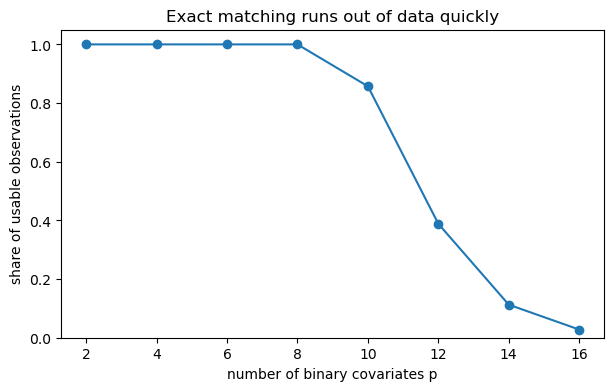

In [10]:
def usable_share(n, p, rng=rng):
    '''Share of obs in cells (defined by p binary covariates) that contain both
    treated and untreated units, with treatment propensity 0.3 everywhere.'''
    X    = rng.binomial(1, 0.5, size=(n, p))
    cell = X @ (2 ** np.arange(p))                     # cell id in {0, ..., 2^p - 1}
    d    = rng.binomial(1, 0.3, n)
    tmp  = pd.DataFrame({"cell": cell, "d": d})
    ok   = tmp.groupby("cell").d.transform(lambda s: 0 < s.mean() < 1)
    return ok.mean()

ps = [2, 4, 6, 8, 10, 12, 14, 16]
curve = pd.DataFrame({"p": ps, "cells 2^p": [2**p for p in ps],
                      "usable share, n=5,000": [usable_share(5_000, p) for p in ps]})
display(curve)

plt.plot(curve.p, curve["usable share, n=5,000"], marker="o")
plt.xlabel("number of binary covariates p"); plt.ylabel("share of usable observations")
plt.title("Exact matching runs out of data quickly"); plt.ylim(0, 1.05); plt.show()

By $p \approx 14$ almost no observation has an exact twin on the other side of the treatment.
Overlap holds in the **population** (every $p(z) = 0.3$), but it fails in the **sample**. This is
the curse of dimensionality applied to $\mu_0(D, Z)$.

That is the bridge to the rest of the course (slide 43). The identification formula
$\theta_{ATE} = E\big[E[Y \mid Z, D=1] - E[Y \mid Z, D=0]\big]$ never changes. What changes is how
we **estimate** the inner conditional expectations: instead of cell means, use LASSO, random
forests, boosting or neural nets (Lectures 1–2) — with care, because plugging an ML fit naively
into the outer average introduces regularization bias. Fixing that is the job of
**double/debiased machine learning** (Chernozhukov et al., 2018, *Econometrics Journal*; CausalML
book ch. 4–5).

---
## Part A wrap-up (3 min)

1. $\text{SDO} = \theta_{ATT} + \text{selection bias}$ is an identity. Identification means arguing
   the second term away.
2. Under unconfoundedness + overlap, the ATE and the ATT are **different weighted averages** of
   the same within-cell effects $\Delta_j$.
3. OLS with dummies is a **third** weighted average, with variance weights (Angrist, 1998).
4. Overlap failure kills the ATE but not necessarily the ATT, and software will not warn you.
5. Unconfoundedness failure is bias, not noise: $n$ does not help.
6. With many controls, the problem becomes *estimating* $E[Y \mid D, Z]$, which is where ML enters.

**Next Friday:** what if no set of observables makes $D$ as good as random, but we have a coin
flip that *nudges* $D$?

---
---
# PART B — Instrumental Variables and LATE  *(Fri 23 Oct, 50 min)*

| Block | Minutes |
|---|---|
| B0 Warm-up | 4 |
| B1 Incomplete randomization and compliance types (slides 13–16) | 9 |
| B2 ITT and the defier problem (slides 17–18) | 8 |
| B3 Ways out: homogeneity and one-sided non-compliance (slides 19–20) | 6 |
| B4 The LATE theorem (slides 21–27) | 10 |
| B5 When uniformity fails | 5 |
| B6 LATE with covariates (slide 28) | 6 |
| Wrap-up | 2 |
| *Take-home: complier characteristics* | — |

**By the end of Part B you should be able to:**
1. Simulate the four principal strata (always-takers, never-takers, compliers, defiers) and say
   which ones are mixed inside the observed treated and untreated groups.
2. Reproduce the slide-18 example where the ITT is zero although every effect is positive.
3. Compute first stage, reduced form, and the Wald ratio, and say *for whom* the Wald ratio is an
   average effect.
4. Show numerically that the Wald ratio equals the ATT under one-sided non-compliance and equals
   the complier ATE under uniformity — and that it equals neither the ATE nor the ATT in general.
5. Use the slide-28 formula when the instrument is only randomized *within* covariate cells.

---
## B0 Warm-up (4 min, no code)

A job-training program has more applicants than seats, so it runs a **lottery**. Winners
($W=1$) are *offered* training. Some winners don't show up. Some losers find a way in anyway (a
sibling program, an appeal, a sympathetic caseworker).

1. The lottery is random. Is *actual* training $D$ random?
2. Who are the people whose training status was decided by the lottery, and who are the people
   for whom the lottery was irrelevant?
3. If the program helps the people who fight their way in the most, will an IV estimate based on
   the lottery capture that?

The answer to (3) is the "L" in LATE.

---
## B1 Incomplete randomization and compliance types (slides 13–16)

Each applicant carries a pair of **potential treatment statuses** $(D(0), D(1))$: what they would
do if they lost and if they won the lottery. These define four types (Angrist, Imbens & Rubin,
1996), the $2 \times 2$ table on slide 16:

| | $D(0) = 0$ | $D(0) = 1$ |
|---|---|---|
| $D(1) = 0$ | never-taker | defier |
| $D(1) = 1$ | complier | always-taker |

Just like $Y(0), Y(1)$, we never see both $D(0)$ and $D(1)$ for anyone.

**Our DGP.** $n = 200{,}000$ applicants; the lottery offers training with probability $2/3$
(the US JTPA experiment also used a 2:1 offer ratio; Bloom et al., 1997). No defiers yet.
Earnings are in \$1,000s. Types differ in **both** baseline earnings and gains, which is what
makes the problem interesting:

| type | share | mean $Y(0)$ | mean effect | story |
|---|---|---|---|---|
| never-taker (NT) | 0.30 | 14 | 0.5 | low attachment, would gain little |
| complier (C) | 0.60 | 18 | 2.0 | train if and only if offered |
| always-taker (AT) | 0.10 | 24 | 4.0 | motivated, gain most, get in regardless |

In [11]:
rng = np.random.default_rng(20261023)

TYPES = ["NT", "C", "AT", "DF"]
BASE  = {"NT": 14.0, "C": 18.0, "AT": 24.0, "DF": 16.0}   # mean Y(0)
GAIN  = {"NT":  0.5, "C":  2.0, "AT":  4.0, "DF":  3.0}   # mean Y(1) - Y(0)
D0    = {"NT": 0, "C": 0, "AT": 1, "DF": 1}
D1    = {"NT": 0, "C": 1, "AT": 1, "DF": 0}

def simulate_lottery(n, shares, p_offer=2/3, rng=rng):
    '''shares: dict type -> probability. Returns God's-eye data.'''
    t  = rng.choice(list(shares), size=n, p=list(shares.values()))
    w  = rng.binomial(1, p_offer, n)                          # the lottery: W indep. of everything
    d0 = np.vectorize(D0.get)(t); d1 = np.vectorize(D1.get)(t)
    y0 = np.vectorize(BASE.get)(t) + rng.normal(0, 3, n)
    y1 = y0 + np.vectorize(GAIN.get)(t) + rng.normal(0, 1, n)
    d  = w * d1 + (1 - w) * d0                                # slide 14: observed treatment
    y  = d * y1 + (1 - d) * y0                                # slide 14: observed outcome
    return pd.DataFrame({"type": t, "w": w, "d0": d0, "d1": d1, "d": d,
                         "y0": y0, "y1": y1, "y": y})

base_shares = {"NT": 0.30, "C": 0.60, "AT": 0.10}
lot = simulate_lottery(200_000, base_shares)
lot.head(8)

,type,w,d0,d1,d,y0,y1,y
0,C,1,0,1,1,15.556,18.514,18.514
1,C,1,0,1,1,20.381,21.811,21.811
2,AT,0,1,1,1,27.208,32.098,32.098
3,C,0,0,1,0,21.646,23.663,21.646
4,AT,1,1,1,1,22.590,24.882,24.882
5,NT,0,0,0,0,16.533,16.734,16.533
6,NT,0,0,0,0,14.701,17.296,14.701
7,C,1,0,1,1,19.322,21.426,21.426


**What we implicitly assumed in writing `simulate_lottery`** (slide 15):
- **SUTVA**: my `d` depends only on *my* `w`; my `y` depends only on *my* `d`. No spillovers
  (e.g. trainees competing with each other for the same jobs).
- **Exclusion**: `y` depends on `w` *only* through `d`. Winning the lottery has no direct effect on
  earnings (e.g. no morale boost). Notice the code literally never uses `w` in building `y0, y1`.
- **Independence**: `w` is drawn without looking at `type`, `y0` or `y1`.

### Exercise B1 (4 min) — the slide-16 question

What types make up each of the four observed $(W, D)$ cells? Cross-tabulate `type` against
`(w, d)` and fill in the blanks below before running it:

| | $D = 0$ | $D = 1$ |
|---|---|---|
| $W = 0$ | ? | ? |
| $W = 1$ | ? | ? |

In [12]:
# ---- EXERCISE B1 ------------------------------------------------------------
pd.crosstab([lot.w, lot.d], lot.type, normalize="index").round(3)
# -----------------------------------------------------------------------------

type    AT     C    NT
w d                   
0 0  0.000 0.667 0.333
  1  1.000 0.000 0.000
1 0  0.000 0.000 1.000
  1  0.144 0.856 0.000

Under no defiers:

| | $D = 0$ | $D = 1$ |
|---|---|---|
| $W = 0$ | NT + C | **AT only** |
| $W = 1$ | **NT only** | C + AT |

Two cells are "pure" and two are mixtures. The observed treated group mixes compliers who won
with always-takers from both arms, and always-takers are the high-baseline, high-gain type. The
naive $D$-comparison is therefore contaminated (slide 17, point 1). Check it:

In [13]:
truth = {
    "ATE":  (lot.y1 - lot.y0).mean(),
    "ATT":  (lot.y1 - lot.y0)[lot.d == 1].mean(),
    "LATE (complier ATE)": (lot.y1 - lot.y0)[lot.type == "C"].mean(),
}
naive = lot.y[lot.d == 1].mean() - lot.y[lot.d == 0].mean()
pd.Series({**truth, "naive E[Y|D=1]-E[Y|D=0]": naive})

ATE                       1.748
ATT                       2.396
LATE (complier ATE)       1.993
naive E[Y|D=1]-E[Y|D=0]   5.986
dtype: float64

Three different *true* parameters (ATE $\approx 1.75$, ATT $\approx 2.4$, complier effect
$\approx 2$) and a naive comparison of about **6**, mostly the baseline gap between always-takers
and never-takers.

---
## B2 ITT and the defier problem (slides 17–18)

Because $W$ is random, $E[Y \mid W=1] - E[Y \mid W=0]$ is a clean causal effect: the effect of
**the offer** (the intention-to-treat, ITT). The derivation on slide 18 is worth doing once:

$$
\begin{aligned}
Y &= Y(0) + D\,[Y(1) - Y(0)], \qquad D = D(0) + W[D(1) - D(0)], \\
E[Y \mid W=1] - E[Y \mid W=0] &\overset{\text{indep.}}{=} E\big[\{D(1) - D(0)\}\{Y(1) - Y(0)\}\big].
\end{aligned}
$$

Since $D(1) - D(0) \in \{-1, 0, 1\}$, that expectation splits into a complier part (weight $+1$)
minus a defier part (weight $-1$). Always- and never-takers contribute **zero**, because the
lottery doesn't move them.

### Exercise B2 (4 min) — reproduce slide 18

Build the slide's population: compliers with effect exactly 1 (share 2/3), defiers with effect
exactly 2 (share 1/3), no one else. Compute the ITT. Then compute the first stage and the Wald
ratio.

In [14]:
# ---- EXERCISE B2 ------------------------------------------------------------
n_s = 300_000
t_s = rng.choice(["C", "DF"], size=n_s, p=[2/3, 1/3])
w_s = rng.binomial(1, 0.5, n_s)
d_s = np.where(t_s == "C", w_s, 1 - w_s)                 # compliers follow W, defiers oppose it
y0_s = rng.normal(10, 3, n_s)
y1_s = y0_s + np.where(t_s == "C", 1.0, 2.0)            # every individual effect is POSITIVE
y_s  = np.where(d_s == 1, y1_s, y0_s)

itt_s = y_s[w_s == 1].mean() - y_s[w_s == 0].mean()
fs_s  = d_s[w_s == 1].mean() - d_s[w_s == 0].mean()
pd.Series({"min individual effect": (y1_s - y0_s).min(),
           "ITT (reduced form)": itt_s,
           "first stage": fs_s,
           "Wald = ITT / first stage": itt_s / fs_s})
# -----------------------------------------------------------------------------

min individual effect      1.000
ITT (reduced form)         0.002
first stage                0.333
Wald = ITT / first stage   0.006
dtype: float64

Exactly the slide's arithmetic: $\tfrac23 \cdot 1 - \tfrac13 \cdot 2 = 0$. The offer moves
compliers *into* training and defiers *out of* it, and their gains cancel. The first stage is
$\tfrac23 - \tfrac13 = \tfrac13 \neq 0$, so relevance holds, yet the Wald ratio is about zero
while the smallest individual effect is $+1$. An IV estimate of zero would be read as "the
program does nothing," which is false for every single person.

This is why **uniformity** (no defiers) is not a technicality. It is what makes the ITT a
weighted average of effects with **non-negative** weights.

---
## B3 Ways out that work in special cases (slides 19–20)

### Homogeneity (slide 19)
If $Y(1) - Y(0) = \theta_0$ for everyone, the ITT is $\theta_0 \times$ first stage, and the ratio
recovers $\theta_0 = $ ATE = ATT. Defiers would no longer be a problem either, since every type
has the same gain. But heterogeneity is the norm (our DGP has gains from 0.5 to 4).

### One-sided non-compliance (slide 20; Bloom, 1984)
If lottery losers **cannot** get in, $D(0) = 0$ for everyone: no always-takers, no defiers. Then
every treated person is a complier who won, so the complier effect *is* the ATT.

### Exercise B3 (4 min)

Simulate a one-sided world: shares `{"NT": 0.35, "C": 0.65}`. Compute the Wald ratio and compare
it with the true ATT, the true complier effect, and the true ATE.

In [15]:
# ---- EXERCISE B3 ------------------------------------------------------------
one = simulate_lottery(200_000, {"NT": 0.35, "C": 0.65})
fs1 = one.d[one.w == 1].mean() - one.d[one.w == 0].mean()
rf1 = one.y[one.w == 1].mean() - one.y[one.w == 0].mean()
te1 = one.y1 - one.y0
pd.Series({"E[D | W=0] (should be 0)": one.d[one.w == 0].mean(),
           "Wald": rf1 / fs1,
           "ATT (true)": te1[one.d == 1].mean(),
           "complier ATE (true)": te1[one.type == "C"].mean(),
           "ATE (true)": te1.mean()})
# -----------------------------------------------------------------------------

E[D | W=0] (should be 0)   0.000
Wald                       2.016
ATT (true)                 1.997
complier ATE (true)        1.998
ATE (true)                 1.473
dtype: float64

Wald $\approx$ ATT $=$ complier effect $\approx 2$, while the ATE $\approx 1.5$ is pulled down by
never-takers who gain only 0.5. One-sided designs are common in practice (an offer you can't get
without winning), which is why "IV identifies the effect of treatment on the treated" is often
said, but it only holds in this case.

---
## B4 The LATE theorem (slides 21–27)

**Assumptions (slides 23–25):**
- 2.1 **Exclusion**: $W$ affects $Y$ only through $D$. *Untestable.*
- 2.2 **Independence**: $W \perp (Y(0), Y(1), D(0), D(1))$. *Satisfied by the lottery; balance
  checks are an indirect test.*
- 2.3 **Relevance**: $E[D \mid W=1] \neq E[D \mid W=0]$. *Directly testable.*
- 2.4 **Uniformity**: $D(1) \ge D(0)$ for everyone (or $\le$ for everyone). *Untestable in
  general*, though it has testable implications (Kitagawa, 2015, *Econometrica*).

**Theorem 2.1 (Imbens & Angrist, 1994).**

$$
\theta_{LATE} \equiv E[Y(1) - Y(0) \mid D(1) \ne D(0)]
= \frac{E[Y \mid W=1] - E[Y \mid W=0]}{E[D \mid W=1] - E[D \mid W=0]} \equiv \theta_{Wald}.
$$

**Proof in two lines** (it is just slide 18 with the defier term deleted). Under uniformity,
$D(1) - D(0) \in \{0, 1\}$, so

$$
\text{ITT} = E[Y(1)-Y(0) \mid \text{C}]\,P(\text{C}), \qquad
\text{first stage} = E[D(1) - D(0)] = P(\text{C}).
$$

Divide. The **diagram on slide 27** is the same statement:
*first stage × second stage = reduced form*, so *second stage = reduced form / first stage*.

### Exercise B4 (6 min)

On `lot` (no defiers, two-sided non-compliance):
1. Compute the first stage, the reduced form, and their ratio.
2. Compute the true complier share and the true complier effect. Match them to (1).
3. Compute 2SLS by hand: regress `d` on `w` and save the fitted values $\hat D$; regress `y` on
   $\hat D$. Show the slope equals the Wald ratio.

In [16]:
# ---- EXERCISE B4 ------------------------------------------------------------
fs = lot.d[lot.w == 1].mean() - lot.d[lot.w == 0].mean()          # first stage
rf = lot.y[lot.w == 1].mean() - lot.y[lot.w == 0].mean()          # reduced form = ITT
wald = rf / fs

share_C = (lot.type == "C").mean()
late    = (lot.y1 - lot.y0)[lot.type == "C"].mean()

# 2SLS by hand (point estimate only -- see note below on standard errors)
lot["d_hat"] = smf.ols("d ~ w", data=lot).fit().fittedvalues
tsls = smf.ols("y ~ d_hat", data=lot).fit().params["d_hat"]

pd.DataFrame({
    "estimate": [fs, rf, wald, tsls],
    "truth": [share_C, late * share_C, late, late],
}, index=["first stage  vs  P(complier)", "reduced form  vs  LATE x P(C)",
          "Wald  vs  LATE", "2SLS  vs  LATE"])
# -----------------------------------------------------------------------------

,estimate,truth
first stage vs P(complier),0.601,0.600
reduced form vs LATE x P(C),1.203,1.197
Wald vs LATE,2.002,1.993
2SLS vs LATE,2.002,1.993


Every row lines up. Two remarks:

- **2SLS = Wald exactly** with one binary instrument and no covariates. The second-stage OLS slope
  is $\mathrm{Cov}(Y, \hat D)/\mathrm{Var}(\hat D) = \mathrm{Cov}(Y, W)/\mathrm{Cov}(D, W)$, and with
  binary $W$ both covariances reduce to differences in means times $\mathrm{Var}(W)$.
- **Don't use the manual second-stage standard errors.** They use residuals $Y - \hat\beta \hat D$
  instead of $Y - \hat\beta D$ and are wrong. Use a proper IV routine (e.g. `linearmodels.IV2SLS`
  or `pyfixest`) for inference.

### Which effect did we get?

In [17]:
pd.Series({"Wald / 2SLS": wald, **truth})

Wald / 2SLS           2.002
ATE                   1.748
ATT                   2.396
LATE (complier ATE)   1.993
dtype: float64

The Wald ratio estimates **the complier effect ($\approx 2$)**. It is not the ATE ($\approx 1.75$)
and it is not the ATT ($\approx 2.4$). Always-takers have the biggest gains, but the lottery never
moves them, so the IV design carries **no information** about their $Y(0)$ or their effect — and
symmetrically for never-takers' $Y(1)$. "You can't always get what you want" (slide 21): the
instrument tells you about the people it moves.

This is the main interpretive point of Imbens & Angrist (1994). A different instrument (say, a
distance-to-training-center instrument) moves a *different* set of compliers and can legitimately
produce a different LATE, with both being "right."

---
## B5 When uniformity fails (5 min)

### Exercise B5

Hold the always-taker and never-taker shares at 0.10 and 0.30 and let a fraction `s_df` of the
remaining 60% be defiers (who, in our DGP, gain 3.0). For `s_df` in `[0, 0.05, 0.10, 0.20, 0.30]`,
record the Wald ratio, the complier effect, and the first stage.

,defier share,first stage,Wald,Wald (theory),complier ATE (true)
0,0.000,0.601,2.011,2.000,2.002
1,0.030,0.540,1.962,1.944,2.003
2,0.060,0.481,1.891,1.875,1.999
3,0.120,0.361,1.660,1.667,2.000
4,0.180,0.240,1.237,1.250,1.999


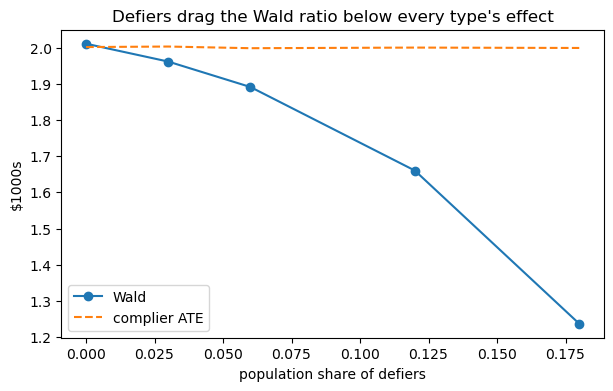

In [18]:
# ---- EXERCISE B5 ------------------------------------------------------------
rows = []
for s_df in [0.0, 0.05, 0.10, 0.20, 0.30]:
    sh = {"NT": 0.30, "AT": 0.10, "C": 0.60 * (1 - s_df), "DF": 0.60 * s_df}
    sim = simulate_lottery(1_000_000, sh)
    fs_i = sim.d[sim.w == 1].mean() - sim.d[sim.w == 0].mean()
    rf_i = sim.y[sim.w == 1].mean() - sim.y[sim.w == 0].mean()
    pC, pD = sh["C"], sh["DF"]
    rows.append({"defier share": pD, "first stage": fs_i, "Wald": rf_i / fs_i,
                 "Wald (theory)": (GAIN["C"] * pC - GAIN["DF"] * pD) / (pC - pD),
                 "complier ATE (true)": (sim.y1 - sim.y0)[sim.type == "C"].mean()})
b5 = pd.DataFrame(rows)
display(b5)

plt.plot(b5["defier share"], b5["Wald"], marker="o", label="Wald")
plt.plot(b5["defier share"], b5["complier ATE (true)"], ls="--", label="complier ATE")
plt.xlabel("population share of defiers"); plt.ylabel("$1000s"); plt.legend()
plt.title("Defiers drag the Wald ratio below every type's effect"); plt.show()
# -----------------------------------------------------------------------------

With defiers, $\text{Wald} = \dfrac{\text{LATE}_C\, P(C) - \text{LATE}_{DF}\, P(DF)}{P(C) - P(DF)}$.
The weights $P(C)/(P(C)-P(DF))$ and $-P(DF)/(P(C)-P(DF))$ sum to one, but one of them is
**negative**, so the ratio is no longer an average of anyone's effect. At 18% defiers the theory
column gives $(2 \times 0.42 - 3 \times 0.18)/0.24 = 1.25$: below the effect of **both** groups
the instrument actually moves (compliers gain 2, defiers gain 3). Push the defier share up and it
keeps falling, and it can turn negative. Note that the first stage stays positive throughout, so
the relevance test gives no warning.

Uniformity is often defensible: it is hard to imagine someone who would enter training *only if
they lost* the lottery. It is much less obvious for instruments like judge assignment or distance,
where different people may respond in opposite directions.

---
## B6 LATE with covariates (slide 28, 6 min)

The program runs in two **sites**, and the lottery is randomized **within** site with different
offer rates: site A offers 80% of applicants, site B only 30%. Site A is also a richer labor
market (higher $Y(0)$), and its applicants have a higher complier share and larger complier
gains.

So $W$ is random **given $Z$ = site**, but not unconditionally: winners over-represent site A.
That is the setting of slide 28: $\{Y(d), D(w)\} \perp W \mid Z$, overlap
$0 < P(W = 1 \mid Z) < 1$, no defiers, and then

$$
\theta_{LATE} = E[Y(1) - Y(0) \mid \text{C}]
= \frac{E\big[E[Y \mid W=1, Z] - E[Y \mid W=0, Z]\big]}{E\big[E[D \mid W=1, Z] - E[D \mid W=0, Z]\big]} .
$$

*A note on wording, flagged because I'm not certain of the intended reading:* slide 28 calls this
the "conditional LATE," but the left-hand side is the **unconditional** complier effect. My
reading is that "conditional" refers to the *assumptions* (independence conditional on $Z$). The
algebra below supports that: the numerator averages $\text{LATE}(z)\,P(C \mid z)$ over $z$, the
denominator averages $P(C \mid z)$, and the ratio is $E[Y(1)-Y(0) \mid C]$ pooled over sites.
Worth confirming with Prof. Fang before presenting.

In [19]:
def simulate_sites(n, rng=rng):
    site = rng.choice(["A", "B"], size=n, p=[0.5, 0.5])
    A = site == "A"
    p_offer = np.where(A, 0.80, 0.30)                         # W random only WITHIN site
    w = rng.binomial(1, p_offer)
    # type shares differ by site (no defiers)
    u = rng.uniform(size=n)
    pC = np.where(A, 0.70, 0.40); pAT = 0.10
    t = np.where(u < pAT, "AT", np.where(u < pAT + pC, "C", "NT"))
    d0 = (t == "AT").astype(int); d1 = np.isin(t, ["AT", "C"]).astype(int)
    d  = w * d1 + (1 - w) * d0
    y0 = np.where(A, 26.0, 16.0) + np.vectorize(BASE.get)(t) - 18 + rng.normal(0, 5, n)
    gain = np.where(t == "C", np.where(A, 3.0, 1.0), np.vectorize(GAIN.get)(t))
    y1 = y0 + gain + rng.normal(0, 1, n)
    y  = d * y1 + (1 - d) * y0
    return pd.DataFrame({"site": site, "type": t, "w": w, "d": d, "y": y, "y0": y0, "y1": y1})

sites = simulate_sites(400_000)
print("P(W=1 | site):"); print(sites.groupby("site").w.mean().round(3))

P(W=1 | site):
site
A   0.800
B   0.300
Name: w, dtype: float64


### Exercise B6

1. Compute the **unconditional** Wald ratio (ignoring site). Is it close to the true complier
   effect?
2. Compute the slide-28 estimator: within-site reduced forms and first stages, each averaged over
   the site distribution $P(Z)$, then the ratio.
3. Compute 2SLS with a site dummy as a control (`y ~ d_hat + site`, with first stage
   `d ~ w + site`). Is it the same number as (2)?

In [20]:
# ---- EXERCISE B6 ------------------------------------------------------------
true_late = (sites.y1 - sites.y0)[sites.type == "C"].mean()

# (1) unconditional Wald -- W is NOT independent of Y(0) without conditioning on site
wald_unc = ((sites.y[sites.w == 1].mean() - sites.y[sites.w == 0].mean()) /
            (sites.d[sites.w == 1].mean() - sites.d[sites.w == 0].mean()))

# (2) slide 28: average within-site differences over P(Z), then take the ratio
g   = sites.groupby("site")
rf_z = g.apply(lambda s: s.y[s.w == 1].mean() - s.y[s.w == 0].mean())
fs_z = g.apply(lambda s: s.d[s.w == 1].mean() - s.d[s.w == 0].mean())
p_z  = g.size() / len(sites)
late_cov = (rf_z * p_z).sum() / (fs_z * p_z).sum()

# (3) 2SLS with an additive site control
sites["d_hat"] = smf.ols("d ~ w + C(site)", data=sites).fit().fittedvalues
tsls_cov = smf.ols("y ~ d_hat + C(site)", data=sites).fit().params["d_hat"]

# weights implied by 2SLS with saturated additive site dummies:  P(z) * Var(W|z) * FS(z)
var_w  = g.w.var(ddof=0)
w_tsls = p_z * var_w * fs_z
w_s28  = p_z * fs_z
display(pd.DataFrame({"reduced form": rf_z, "first stage": fs_z, "site LATE": rf_z / fs_z,
                      "P(Z)": p_z, "slide-28 weight": w_s28 / w_s28.sum(),
                      "2SLS weight": w_tsls / w_tsls.sum()}))
print("2SLS reconstructed from weights:", ((w_tsls / w_tsls.sum()) * rf_z / fs_z).sum())
pd.Series({"true complier ATE": true_late,
           "(1) unconditional Wald": wald_unc,
           "(2) slide-28 estimator": late_cov,
           "(3) 2SLS + site dummy": tsls_cov})
# -----------------------------------------------------------------------------

,reduced form,first stage,site LATE,P(Z),slide-28 weight,2SLS weight
site,,,,,,
A,2.049,0.698,2.936,0.500,0.634,0.569
B,0.401,0.403,0.996,0.500,0.366,0.431


2SLS reconstructed from weights: 2.100214599338425


true complier ATE         2.268
(1) unconditional Wald   11.772
(2) slide-28 estimator    2.226
(3) 2SLS + site dummy     2.100
dtype: float64

**What to see.**

1. The unconditional Wald is badly biased: lottery winners are disproportionately from the
   high-earning site A, so the "reduced form" picks up the site gap in $Y(0)$. This is A2's
   selection-on-observables problem, now hitting the instrument instead of the treatment.
2. The slide-28 estimator recovers the pooled complier effect.
3. 2SLS with an additive site dummy is close but **not identical**. It is also a weighted average
   of the site-specific LATEs, but with weights $\propto P(z)\,\mathrm{Var}(W \mid z)\,\text{FS}(z)$
   instead of the slide-28 weights $\propto P(z)\,\text{FS}(z)$ — the IV analogue of Angrist (1998)
   from Part A. The weight table above reconstructs the 2SLS number exactly. Site A's
   offer rate of 0.8 gives $\mathrm{Var}(W\mid A) = 0.16 < 0.21 = \mathrm{Var}(W \mid B)$, so 2SLS
   shifts weight toward the low-effect site B. Abadie (2003) and, more
   recently, Słoczyński (2024, *"When should we (not) interpret linear IV estimands as LATE?"*)
   study when 2SLS with covariates has a LATE interpretation. *I'm not fully sure of the exact
   publication venue/year of the Słoczyński paper; please verify the citation before giving it to
   students.*

**Bridge to the rest of the course (slide 43).** The numerator and denominator of slide 28 are
both of the form $E[g(1, Z) - g(0, Z)]$ with nuisance functions $E[Y \mid W, Z]$ and
$E[D \mid W, Z]$. With two sites we used cell means. With hundreds of covariates, these are
exactly the conditional expectations we will estimate with ML and plug into a debiased (DML)
estimator.

---
## Part B wrap-up (2 min)

1. A randomized instrument fixes selection into **the offer**, not selection into **treatment**.
2. The ITT averages effects over compliers *minus* defiers. With defiers, it can be zero when every
   effect is positive.
3. Under exclusion, independence, relevance and uniformity: **reduced form / first stage = complier
   ATE** (Imbens & Angrist, 1994). It equals the ATT under one-sided non-compliance, and the ATE
   only under homogeneity.
4. LATE is instrument-specific: it is the effect for the people *this* instrument moves.
5. If the instrument is random only given $Z$, average within-cell reduced forms and first stages
   *before* taking the ratio (slide 28). Additive-control 2SLS gives a different weighting.

---
## Take-home (optional): who are the compliers?

We can never label an individual as a complier, but we **can** describe compliers on average.
Abadie (2003) shows that for any pre-treatment characteristic $X$, under the LATE assumptions,

$$
E[X \mid \text{C}] = \frac{E[XD \mid W=1] - E[XD \mid W=0]}{E[D \mid W=1] - E[D \mid W=0]} .
$$

*Why it works:* $E[XD \mid W=1]$ averages $X$ over compliers and always-takers (weighted by their
shares); $E[XD \mid W=0]$ averages over always-takers only. The difference leaves compliers,
weighted by $P(C)$, which the denominator removes.

Apply it with $X = Y(0)$ replaced by an observed proxy: here, use **pre-program earnings**,
simulated as `y0` plus noise. Compare the estimate with the true complier mean and with the
overall mean. Are compliers positively or negatively selected relative to the whole population?

In [21]:
lot["pre_earn"] = lot.y0 + rng.normal(0, 2, len(lot))       # an observed, pre-treatment X

xd1 = (lot.pre_earn * lot.d)[lot.w == 1].mean()
xd0 = (lot.pre_earn * lot.d)[lot.w == 0].mean()
complier_mean_hat = (xd1 - xd0) / fs

pd.Series({"E[X | complier] (Abadie formula)": complier_mean_hat,
           "E[X | complier] (true)": lot.pre_earn[lot.type == "C"].mean(),
           "E[X] (everyone)": lot.pre_earn.mean(),
           "E[X | always-taker] (true)": lot.pre_earn[lot.type == "AT"].mean()})

E[X | complier] (Abadie formula)   17.987
E[X | complier] (true)             17.989
E[X] (everyone)                    17.395
E[X | always-taker] (true)         24.009
dtype: float64

---
## References

- Abadie, A. (2003). Semiparametric instrumental variable estimation of treatment response models.
  *Journal of Econometrics*, 113(2), 231–263.
- Angrist, J. D. (1998). Estimating the labor market impact of voluntary military service using
  Social Security data on military applicants. *Econometrica*, 66(2), 249–288.
- Angrist, J. D., Imbens, G. W., & Rubin, D. B. (1996). Identification of causal effects using
  instrumental variables. *JASA*, 91(434), 444–455.
- Angrist, J. D., & Pischke, J.-S. (2009). *Mostly Harmless Econometrics*. Princeton UP. §3.3.1, ch. 4.
- Bloom, H. S. (1984). Accounting for no-shows in experimental evaluation designs. *Evaluation
  Review*, 8(2), 225–246.
- Bloom, H. S., Orr, L. L., Bell, S. H., Cave, G., Doolittle, F., Lin, W., & Bos, J. M. (1997).
  The benefits and costs of JTPA Title II-A programs. *Journal of Human Resources*, 32(3), 549–576.
- Chernozhukov, V., Chetverikov, D., Demirer, M., Duflo, E., Hansen, C., Newey, W., & Robins, J.
  (2018). Double/debiased machine learning for treatment and structural parameters.
  *Econometrics Journal*, 21(1), C1–C68.
- Chernozhukov, V., Hansen, C., Kallus, N., Spindler, M., & Syrgkanis, V. (2024). *Applied Causal
  Inference Powered by ML and AI*. Online manuscript.
- Crump, R. K., Hotz, V. J., Imbens, G. W., & Mitnik, O. A. (2009). Dealing with limited overlap
  in estimation of average treatment effects. *Biometrika*, 96(1), 187–199.
- Heckman, J. J., & Vytlacil, E. (2005). Structural equations, treatment effects, and econometric
  policy evaluation. *Econometrica*, 73(3), 669–738.
- Imbens, G. W. (2004). Nonparametric estimation of average treatment effects under exogeneity: A
  review. *REStat*, 86(1), 4–29.
- Imbens, G. W., & Angrist, J. D. (1994). Identification and estimation of local average treatment
  effects. *Econometrica*, 62(2), 467–475.
- Kitagawa, T. (2015). A test for instrument validity. *Econometrica*, 83(5), 2043–2063.
- Neyman, J. (1923/1990). On the application of probability theory to agricultural experiments.
  *Statistical Science*, 5(4), 465–472 (translation).
- Oster, E. (2019). Unobservable selection and coefficient stability. *JBES*, 37(2), 187–204.
- Rosenbaum, P. R. (2002). *Observational Studies*, 2nd ed. Springer.
- Rosenbaum, P. R., & Rubin, D. B. (1983). The central role of the propensity score in
  observational studies for causal effects. *Biometrika*, 70(1), 41–55.
- Rubin, D. B. (1974). Estimating causal effects of treatments in randomized and nonrandomized
  studies. *Journal of Educational Psychology*, 66(5), 688–701.